RITHESH P - 24BAD098

In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Roll Number: 24BAD098")
print("TensorFlow Version:", tf.__version__)

Roll Number: 24BAD098
TensorFlow Version: 2.21.0


In [7]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Image dimensions:", x_train.shape[1:])
print("Number of training images:", len(x_train))
print("Number of testing images:", len(x_test))

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Image dimensions: (28, 28)
Number of training images: 60000
Number of testing images: 10000


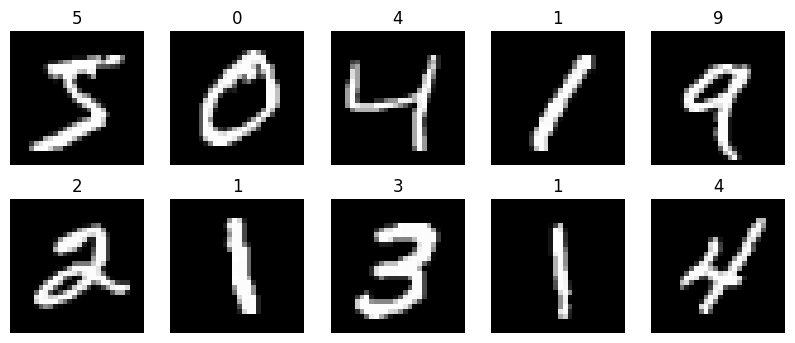

In [8]:
#Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')

plt.show()

In [9]:
# Normalize and flatten images
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 784)
Testing shape: (10000, 784)


In [10]:
#Part B – Implementing encoder and decoder
# Build encoder, decoder and autoencoder
input_dim = 784
latent_dim = 32

input_layer = tf.keras.Input(shape=(input_dim,))

encoded = tf.keras.layers.Dense(128, activation='relu')(input_layer)
encoded = tf.keras.layers.Dense(64, activation='relu')(encoded)
latent = tf.keras.layers.Dense(latent_dim, activation='relu')(encoded)

encoder = tf.keras.Model(input_layer, latent, name="Encoder")

decoder_input = tf.keras.Input(shape=(latent_dim,))

decoded = tf.keras.layers.Dense(64, activation='relu')(decoder_input)
decoded = tf.keras.layers.Dense(128, activation='relu')(decoded)
output_layer = tf.keras.layers.Dense(784, activation='sigmoid')(decoded)

decoder = tf.keras.Model(decoder_input, output_layer, name="Decoder")

autoencoder_output = decoder(encoder(input_layer))

autoencoder = tf.keras.Model(
    input_layer,
    autoencoder_output,
    name="Autoencoder"
)

print("ENCODER SUMMARY")
encoder.summary()

print("DECODER SUMMARY")
decoder.summary()

print("AUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#Part C – Compile and train the autoencoder
#Compile model
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

print("Autoencoder compiled successfully")

Autoencoder compiled successfully


In [12]:
#Train the model
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - loss: 0.2465 - val_loss: 0.1674
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1502 - val_loss: 0.1361
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1312 - val_loss: 0.1253
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.1225 - val_loss: 0.1183
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.1168 - val_loss: 0.1131
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1129 - val_loss: 0.1110
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1100 - val_loss: 0.1073
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1072 - val_loss: 0.1048
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1050 - val_loss: 0.1036
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.1035 - val_loss: 0.1022


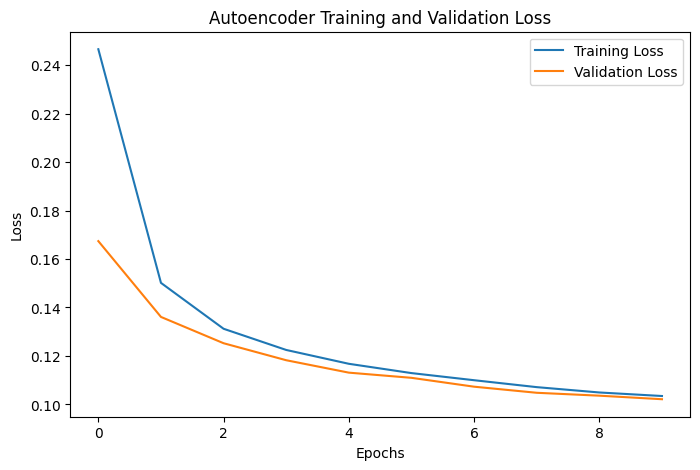

In [13]:
#Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Autoencoder Training and Validation Loss')
plt.legend()
plt.show()

In [14]:
#Part D – Dimensionality reduction, feature learning and reconstruction
# Extract latent features
encoded_images = encoder.predict(x_test)

print("Original dimension:", x_test.shape[1])
print("Latent dimension:", encoded_images.shape[1])
print("Encoded data shape:", encoded_images.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Original dimension: 784
Latent dimension: 32
Encoded data shape: (10000, 32)


In [15]:
#Reconstruct images
reconstructed_images = decoder.predict(encoded_images)

print("Reconstructed shape:", reconstructed_images.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Reconstructed shape: (10000, 784)


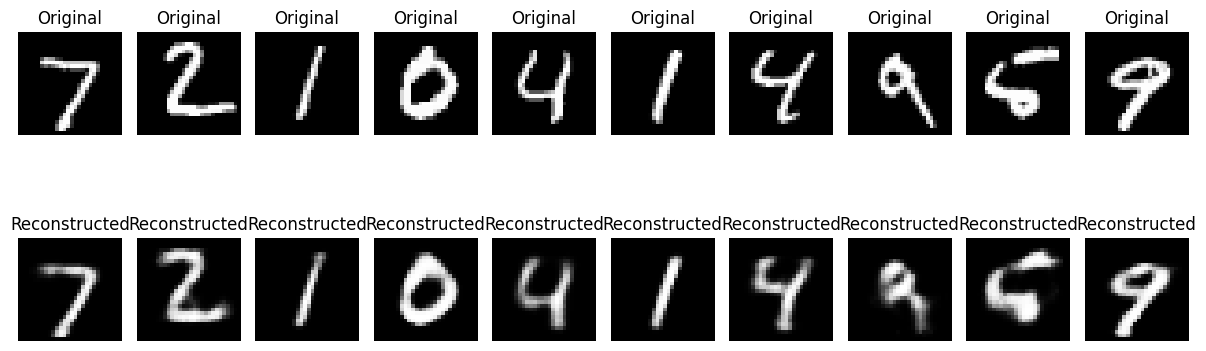

In [16]:
#Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [17]:
# Save the trained model
autoencoder.save("autoencoder_24BAD098.keras")
encoder.save("encoder_24BAD098.keras")
decoder.save("decoder_24BAD098.keras")

print("Models saved successfully")

Models saved successfully
